# BIOT 6900 · Module 7 · My Alzheimer's Knowledge Graph (Neo4j)

**Dhairya Bhatia** · Part I disease: **Alzheimer's disease**

This is the Module 7 assignment: the real-model notebook redone with **my own** data. The genes are my
top 15 Alzheimer's targets from Module 2, carrying the evidence I produced in Modules 2–4 (RNA, protein,
GWAS, druggability, structure). Around them I add public evidence from the Open Targets Platform: Reactome
pathways, drugs and clinical candidates, two related diseases, and HPO phenotypes. The patient layer is the
Module 6 cohort: real 1000 Genomes APOE genotypes and my polygenic risk scores, with the course's
**simulated** disease labels.

| Section | What it does |
|---|---|
| 0 | Connect to my AuraDB instance |
| 1 | Assemble the graph from my Modules 2–6 outputs and Open Targets |
| 2 | Load it into Neo4j |
| 3 | Identifiers |
| 4 | Cypher questions: drugs, repurposing, shared pathways |
| 5 | Biomarker prioritization: PageRank fused with my evidence |
| 6 | Communities and patient stratification |
| 7 | Visualize |

## 0 · Connect

The connection URI is not secret, so it is written here. The username and password are stored as variables of
the `biot6900` conda environment (`conda env config vars`), never in this notebook. The cell reads them from the
environment, or from the environment's saved settings when the kernel starts without activating it.

In [1]:
import os, sys, json
from neo4j import GraphDatabase

NEO4J_URI = "neo4j+s://e1485d82.databases.neo4j.io"   # my AuraDB Free instance "biot6900"

_state = os.path.join(sys.prefix, "conda-meta", "state")
_saved = json.load(open(_state)).get("env_vars", {}) if os.path.exists(_state) else {}
NEO4J_USER = os.environ.get("NEO4J_USERNAME") or _saved.get("NEO4J_USERNAME")
NEO4J_PASSWORD = os.environ.get("NEO4J_PASSWORD") or _saved.get("NEO4J_PASSWORD")

driver = GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASSWORD))

def run_query(cypher, **params):
    """Run Cypher and return rows as a list of dicts."""
    with driver.session() as session:
        return [r.data() for r in session.run(cypher, **params)]

try:
    driver.verify_connectivity()
    print("Connected to Neo4j.")
except Exception as e:
    print("Not connected. Check the instance is running (AuraDB Free pauses when idle). Details:", e)

Connected to Neo4j.


## 1 · The data

**My evidence (Modules 2–4).** The 15 genes and their RNA change, protein change and GWAS strength come from
`module2/targets_ad.csv`; the druggability scores (small molecule, antibody) and final rank from
`module3/targets_ad_w3.csv`; the structure calls for ITGAX and APLNR from `module4/structure_assessment_ad.csv`.

**Public evidence (Open Targets Platform).** `kg_data/` holds what `scripts/build_kg_data.py` fetched for these 15
genes: each gene's Open Targets association score with Alzheimer's disease, its Reactome pathways, the drugs and
clinical candidates acting on it, association scores with candidate related diseases, and HPO phenotypes. The
script kept the two related diseases that share the most of my genes (score ≥ 0.1): **Parkinson disease** (4 genes)
and **schizophrenia** (3 genes).

**Patients (Module 6).** 200 people from the Module 6 cohort, 40 per ancestry group, sampled at random. Their APOE
genotypes are real (1000 Genomes) and their PRS percentile is from my Module 6 score; their case/control label is
the course's **simulation**, not a diagnosis.

In [2]:
import numpy as np
import pandas as pd
import networkx as nx

M2, M3, M4, M6 = "../module2", "../module3", "../module4", "../module6"
top = pd.read_csv(f"{M2}/targets_ad.csv")                      # my 15 genes, Module 2 evidence
w3 = pd.read_csv(f"{M3}/targets_ad_w3.csv")                    # Module 3 druggability and final rank
s4 = pd.read_csv(f"{M4}/structure_assessment_ad.csv")          # Module 4 structure calls
kg = {n: pd.read_csv(f"kg_data/{n}.csv") for n in ["genes", "pathways", "drugs", "related", "phenotypes"]}
dis = json.load(open("kg_data/diseases.json"))
AD = dis["alzheimers"][1]
RELATED = [name for _, name in dis["related"]]
SHORTLIST = ["APLNR", "ITGAX", "PECAM1", "HLA-DRB1", "APOE"]   # my Portfolio 1 shortlist

genes = (top[["gene", "rank", "rna_lfc", "prot_lfc", "neglog10p", "score", "concordant"]]
         .merge(w3[["gene", "p_sm", "p_ab", "rank"]].rename(columns={"rank": "final_rank"}), on="gene")
         .merge(kg["genes"], on="gene")
         .merge(s4[["gene", "mean_pLDDT", "druggability_call"]], on="gene", how="left"))
genes["shortlist"] = genes.gene.isin(SHORTLIST)
genes.round(3)

,gene,rank,rna_lfc,prot_lfc,neglog10p,score,concordant,p_sm,p_ab,final_rank,ensembl,ot_ad_score,mean_pLDDT,druggability_call,shortlist
0,HLA-DRA,1,0.803,0.136,16.699,0.957,True,0.010,0.184,3,ENSG00000204287,0.031,NaN,NaN,False
1,HLA-DRB1,2,0.662,0.102,22.523,0.955,True,0.014,0.269,2,ENSG00000196126,0.081,NaN,NaN,True
2,APOC1,3,0.506,-0.229,672.699,0.949,False,0.001,0.253,5,ENSG00000130208,0.574,NaN,NaN,False
3,PECAM1,4,0.857,0.090,16.523,0.939,True,0.021,0.883,1,ENSG00000261371,0.370,NaN,NaN,True
4,MTSS2,5,0.641,-0.100,13.523,0.913,False,0.117,0.010,8,ENSG00000132613,0.401,NaN,NaN,False
5,ITGAX,6,0.702,0.119,11.699,0.912,True,0.214,0.590,4,ENSG00000140678,0.234,88.0,Possible but uncertain,True
6,GMPR,7,1.036,0.227,10.097,0.910,True,0.172,0.000,9,ENSG00000137198,0.280,NaN,NaN,False
7,RPH3A,8,-1.159,-0.134,10.046,0.904,True,0.092,0.000,12,ENSG00000089169,0.252,NaN,NaN,False
8,NRXN3,9,-0.637,0.062,22.000,0.904,False,0.440,0.122,7,ENSG00000021645,0.212,NaN,NaN,False
9,APLNR,10,1.281,0.100,10.523,0.902,True,0.675,0.035,6,ENSG00000134817,0.021,81.7,Structure supports a small-molecule pocket,True


In [3]:
# ---- nodes: name -> properties (each with a kind) ----
NODES, EDGES = {}, []
def node(name, kind, **props):
    NODES.setdefault(name, {"kind": kind}).update({k: v for k, v in props.items() if pd.notna(v)})
def edge(src, rel, dst, **props):
    EDGES.append({"src": src, "dst": dst, "rel": rel, **props})

for g in genes.itertuples():
    node(g.gene, "gene", ensembl=g.ensembl, module2_rank=int(g.rank), final_rank=int(g.final_rank),
         rna_lfc=round(g.rna_lfc, 3), prot_lfc=round(g.prot_lfc, 3), gwas_neglog10p=round(g.neglog10p, 1),
         module2_score=round(g.score, 3), concordant=bool(g.concordant), p_sm=round(g.p_sm, 3), p_ab=round(g.p_ab, 3),
         mean_pLDDT=g.mean_pLDDT, structure_call=g.druggability_call, shortlist=bool(g.shortlist))
    node(AD, "disease")
    edge(g.gene, "ASSOCIATED_WITH", AD, gwas_neglog10p=round(g.neglog10p, 1), ot_score=g.ot_ad_score, source="Module 2 + Open Targets")

for r in kg["related"][(kg["related"].score >= 0.1) & kg["related"].disease.isin(RELATED)].itertuples():
    node(r.disease, "disease")
    edge(r.gene, "ASSOCIATED_WITH", r.disease, ot_score=r.score, source="Open Targets")

DISEASE_NAMES = {AD.lower(), *(d.lower() for d in RELATED)}
for r in kg["phenotypes"].itertuples():
    if r.phenotype.lower() in DISEASE_NAMES:      # HPO also has terms named after the disease itself; skip them
        continue
    node(r.phenotype, "phenotype", hpo=r.hpo)
    edge(r.disease, "HAS_PHENOTYPE", r.phenotype)

for r in kg["pathways"].itertuples():
    node(r.pathway, "pathway", reactome=r.pathway_id, top_level=r.top_level)
    edge(r.gene, "PARTICIPATES_IN", r.pathway)

drugs = kg["drugs"]
# the same drug can be listed twice, as itself and as a salt ("Mipomersen" and "Mipomersen sodium"): keep one
drugs = drugs[~drugs.apply(lambda r: any(r.drug != o and r.drug.startswith(o + " ") for o in drugs[drugs.gene == r.gene].drug), axis=1)]
for r in drugs.itertuples():
    node(r.drug.title(), "drug", drug_type=r.drug_type, stage=r.stage, indications=", ".join(json.loads(r.indications)))
    edge(r.drug.title(), "TARGETS", r.gene)

# ---- APOE variants and the Module 6 patients ----
node("rs429358 (APOE e4)", "variant", rsid="rs429358", allele="C")
node("rs7412 (APOE e2)", "variant", rsid="rs7412", allele="T")
edge("rs429358 (APOE e4)", "OCCURS_IN", "APOE"); edge("rs7412 (APOE e2)", "OCCURS_IN", "APOE")

geno, meta = pd.read_csv(f"{M6}/data/genotypes.csv"), pd.read_csv(f"{M6}/data/meta.csv")
score, vt = pd.read_csv(f"{M6}/data/score.csv"), pd.read_csv(f"{M6}/data/variants.csv").set_index("variant")
snps = list(score.variant); G6 = geno[snps].to_numpy(float)
flip = score.effect_allele.to_numpy() == vt.loc[snps, "ref"].to_numpy(); G6[:, flip] = 2 - G6[:, flip]
meta["prs_percentile"] = (pd.Series(G6 @ score.weight.to_numpy()).rank(pct=True) * 100).round(1)
meta["n_e4"] = geno["rs429358"] if vt.loc["rs429358", "alt"] == "C" else 2 - geno["rs429358"]
meta["n_e2"] = geno["rs7412"] if vt.loc["rs7412", "alt"] == "T" else 2 - geno["rs7412"]
def apoe(r):
    n3 = max(0, 2 - r.n_e2 - r.n_e4)
    return "/".join(["e2"] * int(r.n_e2) + ["e3"] * int(n3) + ["e4"] * int(r.n_e4))
meta["apoe_genotype"] = meta.apply(apoe, axis=1)
cohort = meta.groupby("ancestry").sample(n=40, random_state=7)
for p in cohort.itertuples():
    node(p.sample_id, "patient", ancestry=p.ancestry, age=round(p.age, 1), status="case" if p.phenotype == 1 else "control",
         apoe_genotype=p.apoe_genotype, prs_percentile=p.prs_percentile)
    if p.n_e4: edge(p.sample_id, "CARRIES", "rs429358 (APOE e4)", copies=int(p.n_e4))
    if p.n_e2: edge(p.sample_id, "CARRIES", "rs7412 (APOE e2)", copies=int(p.n_e2))

print(pd.Series([d["kind"] for d in NODES.values()]).value_counts().to_string())
print("edges:", len(EDGES))

patient      200
phenotype    140
pathway       50
gene          15
drug           5
disease        3
variant        2
edges: 329


## 2 · Load the property graph into Neo4j

Same pattern as the worked example: every node gets its specific label and a shared `:Entity` label with a
unique `name`, and rows are loaded in batches with `UNWIND`. `RESET` clears this instance first, so a re-run
gives exactly the same graph. The instance is used only for this assignment.

In [4]:
RESET = True
if RESET:
    run_query("MATCH (n) DETACH DELETE n")

run_query("CREATE CONSTRAINT entity_name IF NOT EXISTS FOR (n:Entity) REQUIRE n.name IS UNIQUE")
KIND_LABEL = {"gene": "Gene", "disease": "Disease", "phenotype": "Phenotype", "pathway": "Pathway",
              "drug": "Drug", "variant": "Variant", "patient": "Patient"}
for kind, label in KIND_LABEL.items():
    rows = [dict(name=n, **{k: v for k, v in d.items() if k != "kind"}) for n, d in NODES.items() if d["kind"] == kind]
    if rows:
        run_query(f"UNWIND $rows AS row MERGE (e:{label}:Entity {{name: row.name}}) SET e += row", rows=rows)

from collections import defaultdict
by_rel = defaultdict(list)
for e in EDGES:
    by_rel[e["rel"]].append({"src": e["src"], "dst": e["dst"], "props": {k: v for k, v in e.items() if k not in ("src", "dst", "rel")}})
for rel, rows in by_rel.items():
    run_query(f"""UNWIND $rows AS row
                  MATCH (a:Entity {{name: row.src}}) MATCH (b:Entity {{name: row.dst}})
                  MERGE (a)-[r:{rel}]->(b) SET r += row.props""", rows=rows)

print(pd.DataFrame(run_query("MATCH (n) RETURN [l IN labels(n) WHERE l <> 'Entity'][0] AS label, count(*) AS n ORDER BY n DESC")).to_string(index=False))
print("relationships:", run_query("MATCH ()-[r]->() RETURN count(r) AS n")[0]["n"])

    label   n
  Patient 200
Phenotype 140
  Pathway  50
     Gene  15
     Drug   5
  Disease   3
  Variant   2
relationships: 329


## 3 · Identifiers

My Module 2 table is keyed on gene symbols; Open Targets is keyed on Ensembl ids. The build script resolved each
symbol to one Ensembl id through the Open Targets search, so every gene is one node and the public evidence
attaches to it. The table shows the mapping; any symbol that resolved to the wrong id would break the edges silently.

In [5]:
pd.DataFrame(run_query("MATCH (g:Gene) RETURN g.name AS symbol, g.ensembl AS ensembl ORDER BY g.module2_rank"))

,symbol,ensembl
0,HLA-DRA,ENSG00000204287
1,HLA-DRB1,ENSG00000196126
2,APOC1,ENSG00000130208
3,PECAM1,ENSG00000261371
4,MTSS2,ENSG00000132613
5,ITGAX,ENSG00000140678
6,GMPR,ENSG00000137198
7,RPH3A,ENSG00000089169
8,NRXN3,ENSG00000021645
9,APLNR,ENSG00000134817


## 4 · Questions in Cypher

**Drugs that act on my Alzheimer's genes (2 hops).**

In [6]:
pd.DataFrame(run_query("""
    MATCH (d:Drug)-[:TARGETS]->(g:Gene)-[:ASSOCIATED_WITH]->(ad:Disease {name: $ad})
    RETURN d.name AS drug, d.drug_type AS type, d.stage AS furthest_stage, g.name AS gene,
           g.shortlist AS on_my_shortlist, d.indications AS indications
    ORDER BY gene, drug""", ad=AD))

,drug,type,furthest_stage,gene,on_my_shortlist,indications
0,Apelin,Unknown,PHASE_2,APLNR,True,"Hyponatremia, heart failure, pulmonary arteria..."
1,Mipomersen,Oligonucleotide,APPROVAL,APOB,False,"Hypercholesterolemia, atherosclerosis, cardiov..."
2,Apolizumab,Antibody,PHASE_2,HLA-DRB1,True,"B-cell chronic lymphocytic leukemia, Hodgkins ..."
3,Lym-1,Unknown,PHASE_1,HLA-DRB1,True,non-Hodgkin lymphoma
4,Plovamer Acetate,Small molecule,PHASE_2,HLA-DRB1,True,"multiple sclerosis symptom measurement, relaps..."


**Repurposing walk (5 hops):** drugs on genes of a related disease that shares a symptom with Alzheimer's.

In [7]:
pd.DataFrame(run_query("""
    MATCH (d:Drug)-[:TARGETS]->(g:Gene)-[:ASSOCIATED_WITH]->(other:Disease)
          -[:HAS_PHENOTYPE]->(p:Phenotype)<-[:HAS_PHENOTYPE]-(ad:Disease {name: $ad})
    WHERE other <> ad
    RETURN d.name AS repurposing_candidate, g.name AS gene, other.name AS via_disease,
           collect(DISTINCT p.name) AS shared_symptoms
    ORDER BY repurposing_candidate""", ad=AD))

,repurposing_candidate,gene,via_disease,shared_symptoms
0,Apolizumab,HLA-DRB1,Parkinson disease,"[Depression, Parkinsonism]"
1,Lym-1,HLA-DRB1,Parkinson disease,"[Depression, Parkinsonism]"
2,Plovamer Acetate,HLA-DRB1,Parkinson disease,"[Depression, Parkinsonism]"


**Which pathways connect my shortlist?** Pathways shared by two or more of my genes, and which genes meet there.

In [8]:
pd.DataFrame(run_query("""
    MATCH (g:Gene)-[:PARTICIPATES_IN]->(p:Pathway)
    WITH p, collect(g.name) AS genes, sum(CASE WHEN g.shortlist THEN 1 ELSE 0 END) AS shortlist_genes
    WHERE size(genes) >= 2
    RETURN p.name AS pathway, p.top_level AS area, genes, shortlist_genes
    ORDER BY shortlist_genes DESC, size(genes) DESC, pathway"""))

,pathway,area,genes,shortlist_genes
0,Cell surface interactions at the vascular wall,Hemostasis,"[PECAM1, ITGAX, APOB]",2
1,Integrin cell surface interactions,Extracellular matrix organization,"[PECAM1, ITGAX]",2
2,Neutrophil degranulation,Immune System,"[PECAM1, ITGAX]",2
3,Affinity selection of immunoglobulins,Immune System,"[HLA-DRA, HLA-DRB1]",1
4,Chylomicron assembly,Transport of small molecules,"[APOE, APOB]",1
5,Chylomicron clearance,Transport of small molecules,"[APOE, APOB]",1
6,Chylomicron remodeling,Transport of small molecules,"[APOE, APOB]",1
7,Co-inhibition by PD-1,Immune System,"[HLA-DRA, HLA-DRB1]",1
8,Differentiation of Circulating Monocytes,Developmental Biology,"[HLA-DRA, ITGAX]",1
9,Downstream TCR signaling,Immune System,"[HLA-DRA, HLA-DRB1]",1


## 5 · Biomarker prioritization

PageRank runs client-side in NetworkX on the same nodes and edges, so it works on AuraDB Free. I leave the 200
patients out of PageRank: they only link to the two APOE variants, so including them would rank APOE by the size
of my sample rather than by the biology. I then fuse four percentile ranks with equal weight: PageRank (network
position), my Module 2 score (RNA, protein, GWAS), my best Module 3 druggability score, and the Open Targets
association with Alzheimer's.

In [9]:
G = nx.DiGraph()
for name, d in NODES.items():
    G.add_node(name, **d)
for e in EDGES:
    G.add_edge(e["src"], e["dst"], **{k: v for k, v in e.items() if k not in ("src", "dst")})
core = G.subgraph([n for n, d in G.nodes(data=True) if d["kind"] != "patient"])

pr = nx.pagerank(core.to_undirected())
bm = pd.DataFrame([{"gene": n, "pagerank": pr[n], "module2_score": d["module2_score"],
                    "druggability": max(d["p_sm"], d["p_ab"]), "ot_ad_score": genes.set_index("gene").loc[n, "ot_ad_score"],
                    "shortlist": d["shortlist"]}
                   for n, d in core.nodes(data=True) if d["kind"] == "gene"])
for c in ["pagerank", "module2_score", "druggability", "ot_ad_score"]:
    bm[c + "_pct"] = bm[c].rank(pct=True)
bm["fused"] = bm[[c for c in bm if c.endswith("_pct")]].mean(axis=1)
bm = bm.sort_values("fused", ascending=False).reset_index(drop=True)
bm.index += 1
bm[["gene", "pagerank", "module2_score", "druggability", "ot_ad_score", "fused", "shortlist"]].round(3)

,gene,pagerank,module2_score,druggability,ot_ad_score,fused,shortlist
1,PECAM1,0.015,0.939,0.883,0.370,0.833,True
2,APOC1,0.010,0.949,0.253,0.574,0.733,False
3,ITGAX,0.011,0.912,0.590,0.234,0.683,True
4,HLA-DRB1,0.021,0.955,0.269,0.081,0.650,True
5,APOE,0.028,0.902,0.015,0.788,0.608,True
6,HLA-DRA,0.016,0.957,0.184,0.031,0.600,False
7,APOB,0.036,0.897,0.149,0.327,0.567,False
8,GMPR,0.006,0.910,0.172,0.280,0.517,False
9,NRXN3,0.006,0.904,0.440,0.212,0.508,False
10,MTSS2,0.002,0.913,0.117,0.401,0.500,False


## 6 · Communities and patient stratification

**Communities** (modularity-based, on the same graph without patients) group genes with the pathways, diseases
and drugs they share.

In [10]:
from networkx.algorithms.community import greedy_modularity_communities
comms = greedy_modularity_communities(core.to_undirected(), seed=7) if "seed" in greedy_modularity_communities.__code__.co_varnames \
        else greedy_modularity_communities(core.to_undirected())
summary = []
for i, c in enumerate(sorted(comms, key=len, reverse=True)):
    kinds = pd.Series([G.nodes[n]["kind"] for n in c]).value_counts().to_dict()
    summary.append({"community": i, "size": len(c), "genes": sorted(n for n in c if G.nodes[n]["kind"] == "gene"),
                    "diseases": sorted(n for n in c if G.nodes[n]["kind"] == "disease"), "kinds": kinds})
pd.DataFrame(summary)

,community,size,genes,diseases,kinds
0,0,104,[],[schizophrenia],"{'phenotype': 103, 'disease': 1}"
1,1,29,"[APLNR, GMPR, MOG, MTSS2, NRXN3, PLEC, RPH3A, ...",[Alzheimer disease],"{'phenotype': 11, 'gene': 8, 'pathway': 8, 'dr..."
2,2,29,"[APOB, APOC1, APOE]",[],"{'pathway': 23, 'gene': 3, 'variant': 2, 'drug..."
3,3,27,[],[Parkinson disease],"{'phenotype': 26, 'disease': 1}"
4,4,14,"[HLA-DRA, HLA-DRB1]",[],"{'pathway': 9, 'drug': 3, 'gene': 2}"
5,5,12,"[ITGAX, PECAM1]",[],"{'pathway': 10, 'gene': 2}"


**Patient stratification** in Cypher: case rate and mean PRS percentile by APOE genotype. The labels are the
course's simulation, so this shows the method rather than real risk.

In [11]:
pd.DataFrame(run_query("""
    MATCH (p:Patient)
    RETURN p.apoe_genotype AS genotype, count(*) AS n,
           sum(CASE WHEN p.status = 'case' THEN 1 ELSE 0 END) AS cases,
           round(100.0 * avg(CASE WHEN p.status = 'case' THEN 1.0 ELSE 0.0 END), 1) AS case_rate_pct,
           round(avg(p.prs_percentile), 1) AS mean_prs_percentile
    ORDER BY mean_prs_percentile DESC"""))

,genotype,n,cases,case_rate_pct,mean_prs_percentile
0,e4/e4,5,2,40.0,99.3
1,e3/e4,50,21,42.0,86.3
2,e2/e4,3,3,100.0,77.0
3,e3/e3,122,28,23.0,41.0
4,e2/e3,20,8,40.0,14.3


In [12]:
# e4 carriers against non-carriers within each ancestry group (variant-level link, back in Neo4j)
pd.DataFrame(run_query("""
    MATCH (p:Patient)
    OPTIONAL MATCH (p)-[:CARRIES]->(v:Variant {rsid: 'rs429358'})
    WITH p, v IS NOT NULL AS e4_carrier
    RETURN p.ancestry AS ancestry, e4_carrier, count(*) AS n,
           round(100.0 * avg(CASE WHEN p.status = 'case' THEN 1.0 ELSE 0.0 END), 1) AS case_rate_pct,
           round(avg(p.prs_percentile), 1) AS mean_prs_percentile
    ORDER BY ancestry, e4_carrier"""))

,ancestry,e4_carrier,n,case_rate_pct,mean_prs_percentile
0,AFR,False,21,38.1,55.2
1,AFR,True,19,47.4,91.3
2,AMR,False,33,36.4,39.3
3,AMR,True,7,57.1,84.4
4,EAS,False,35,14.3,29.3
5,EAS,True,5,40.0,82.0
6,EUR,False,24,25.0,37.2
7,EUR,True,16,37.5,87.7
8,SAS,False,29,17.2,31.6
9,SAS,True,11,45.5,82.4


## 7 · Visualize

The graph without patients. Pathways are shown only when two or more of my genes share them, so the figure stays
readable; the full graph is in Neo4j Browser.

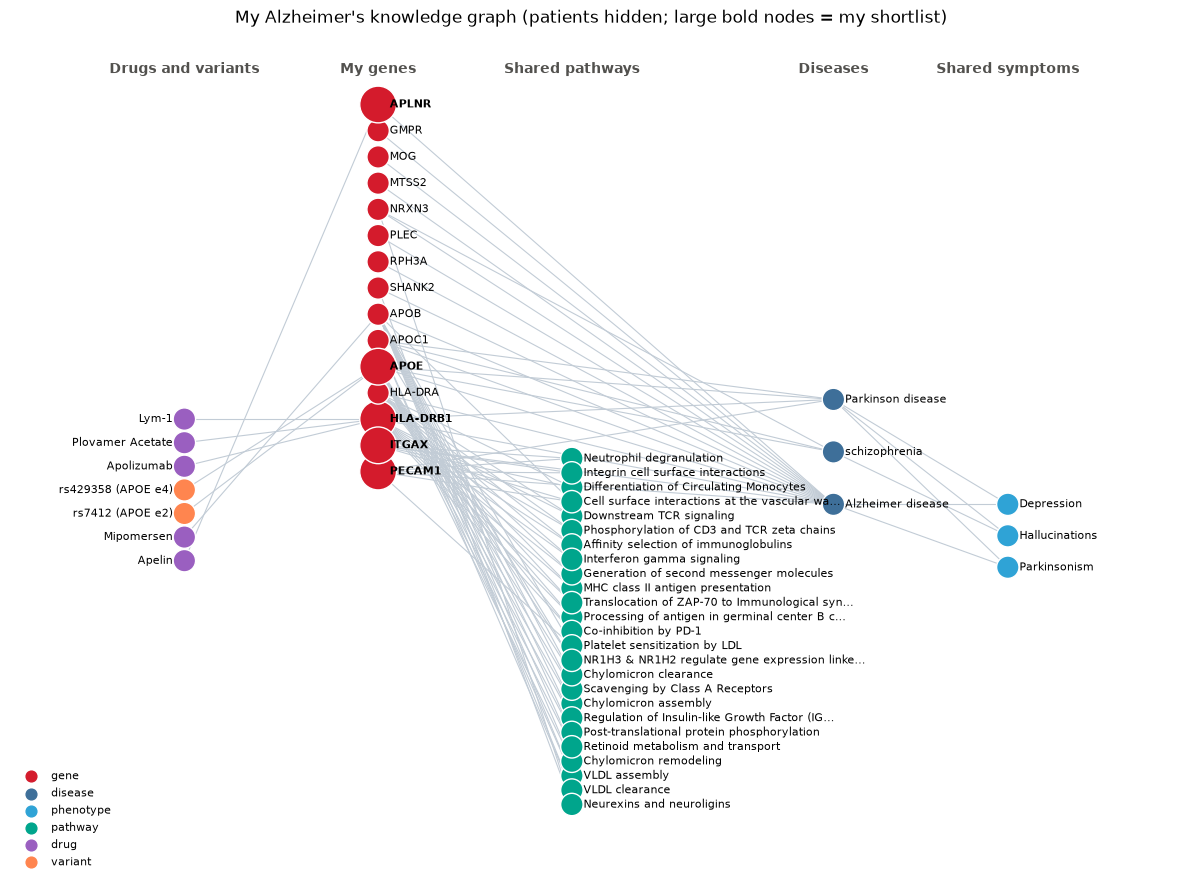

In [13]:
import matplotlib.pyplot as plt

KIND_COLOR = {"gene": "#D41B2C", "disease": "#3E6F99", "phenotype": "#2FA3D6", "pathway": "#00A58C",
              "drug": "#9A5FC0", "variant": "#FF854F"}
# columns read left to right: drugs and variants -> my genes -> shared pathways -> diseases -> shared symptoms
shared_pw = [n for n, d in core.nodes(data=True) if d["kind"] == "pathway" and core.in_degree(n) >= 2]
shared_ph = [n for n, d in core.nodes(data=True) if d["kind"] == "phenotype" and core.in_degree(n) >= 2]
gene_order = sorted([n for n, d in core.nodes(data=True) if d["kind"] == "gene"],
                    key=lambda g: (min(i for i, c in enumerate(comms) if g in c), g))
y = {g: -i for i, g in enumerate(gene_order)}

def spread(names, x, ref, gap=0.9):
    """place nodes at the mean height of the genes they touch, then push apart so labels don't overlap"""
    want = sorted(names, key=lambda n: np.mean([y[g] for g in ref(n)]))
    pos, last = {}, None
    for n in want:
        h = np.mean([y[g] for g in ref(n)])
        h = h if last is None else min(h, last - gap)
        pos[n] = (x, h); last = h
    return pos

genes_of = lambda n: [g for g in nx.all_neighbors(core, n) if g in y]
pos = {g: (0, y[g]) for g in gene_order}
pos |= spread([n for n, d in core.nodes(data=True) if d["kind"] in ("drug", "variant")], -1, genes_of)
pos |= spread(shared_pw, 1, genes_of, gap=0.55)
dis_nodes = [n for n, d in core.nodes(data=True) if d["kind"] == "disease"]
pos |= spread(dis_nodes, 2.35, genes_of, gap=2)
pos |= {p: (3.25, pos[dis_nodes[0]][1] - 1.2 * i) for i, p in enumerate(sorted(shared_ph))}
H = core.subgraph(pos)

fig, ax = plt.subplots(figsize=(15, 11))
nx.draw_networkx_edges(H, pos, ax=ax, edge_color="#C2CCD6", width=0.8, arrows=False)
nx.draw_networkx_nodes(H, pos, ax=ax, node_size=[700 if H.nodes[n].get("shortlist") else 260 for n in H],
                       node_color=[KIND_COLOR[H.nodes[n]["kind"]] for n in H], edgecolors="white")
for n, (x0, y0) in pos.items():
    left = x0 < 0
    ax.text(x0 + (-0.06 if left else 0.06), y0, n if len(n) < 46 else n[:44] + "…", fontsize=8,
            ha="right" if left else "left", va="center", fontweight="bold" if H.nodes[n].get("shortlist") else "normal")
for i, (k, c) in enumerate(KIND_COLOR.items()):
    ax.scatter([], [], color=c, s=60, label=k)
for x0, t in [(-1, "Drugs and variants"), (0, "My genes"), (1, "Shared pathways"), (2.35, "Diseases"), (3.25, "Shared symptoms")]:
    ax.text(x0, 1.2, t, ha="center", fontsize=10, fontweight="bold", color="#52514e")
ax.legend(frameon=False, loc="lower left", fontsize=8)
ax.set_xlim(-1.9, 4.1); ax.axis("off")
ax.set_title("My Alzheimer's knowledge graph (patients hidden; large bold nodes = my shortlist)")
plt.savefig("figures/kg_overview.png", dpi=180, bbox_inches="tight"); plt.show()


## 8 · What I built

| Step | Where |
|---|---|
| A real database holding my Modules 2–6 evidence | §1–2 |
| Cypher: drugs on my genes, a repurposing walk, shared pathways | §4 |
| Biomarker prioritization: PageRank fused with my evidence | §5 |
| Communities and patient stratification (APOE genotype, PRS) | §6 |
| Figure | §7, saved to `figures/kg_overview.png` |

The interpretation is in `REPORT.pdf`.

In [14]:
driver.close()